# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
# !pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

In [2]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# fix: newer scipy removed .getnnz from sparse arrays, which older scanpy still calls in sc.pp.neighbors
import scipy.sparse as sp
if not hasattr(sp.csr_array, "getnnz"):
    sp.csr_array.getnnz = lambda self, axis=None: sp.csr_matrix(self).getnnz(axis=axis)

# fix: umap-learn 0.6 needs contiguous neighbor arrays, older scanpy passes a reshaped view
import umap.umap_ as _umap
if not getattr(_umap.fuzzy_simplicial_set, "_patched", False):
    _fss = _umap.fuzzy_simplicial_set
    def _fss_contig(*args, knn_indices=None, knn_dists=None, **kw):
        if knn_indices is not None: knn_indices = np.ascontiguousarray(knn_indices)
        if knn_dists is not None: knn_dists = np.ascontiguousarray(knn_dists)
        return _fss(*args, knn_indices=knn_indices, knn_dists=knn_dists, **kw)
    _fss_contig._patched = True
    _umap.fuzzy_simplicial_set = _fss_contig

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


GPU available: False
scanpy 1.11.5 | squidpy 1.8.2


/var/folders/4_/88nmgg011p36zdz6mwstpv380000gn/T/ipykernel_50888/4260656564.py:32: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [3]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "malignant" in ct: return "Epithelial/Tumor"   # fix: "malignant cell" contains "t cell", so it was landing in T
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 1,101,430


/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



20,000 cells from 10 donors
cell_type_broad
Epithelial/Tumor    9768
Other               3125
T                   2505
Endothelial         1466
Macrophage          1260
Fibroblast          1118
B                    586
Monocyte              73
NK                    61
DC                    38
Name: count, dtype: int64


/var/folders/4_/88nmgg011p36zdz6mwstpv380000gn/T/ipykernel_50888/2102480458.py:28: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


In [4]:
print("donors:", adata.obs["donor_id"].nunique())
print(adata.obs["assay"].astype(str).value_counts())

donors: 10
assay
10x 3' v3    13922
10x 3' v2     4078
10x 5' v2     2000
Name: count, dtype: int64


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
try:
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="donor_id")
except ValueError:
    # loess fit failed for one donor ("reciprocal condition number"), retry with a wider span
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts", batch_key="donor_id", span=1.0)
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [6]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

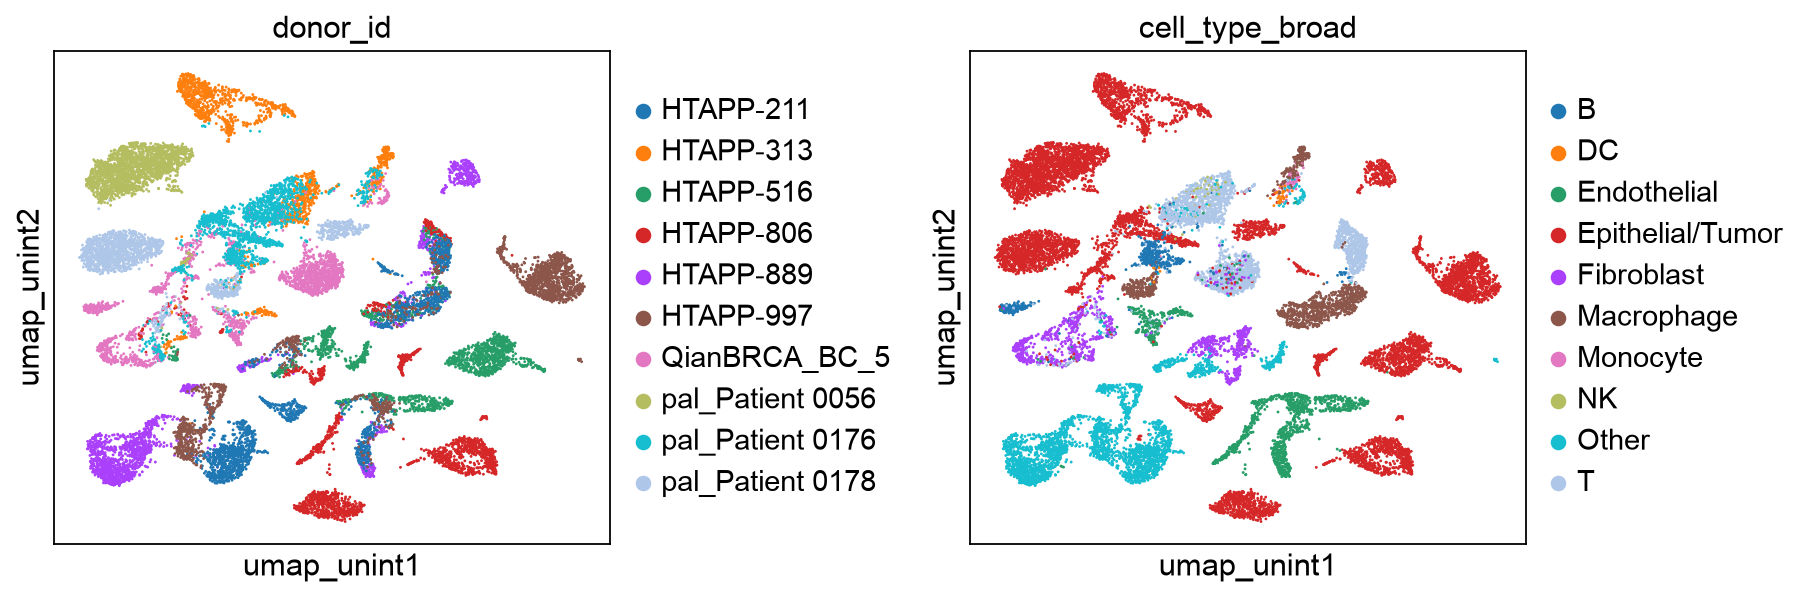

In [7]:
# TODO: plot the unintegrated UMAP colored by donor and by cell type.
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5)

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

It’s organised by donor. Each patient’s tumour cells sit in their own island like HTAPP-806, HTAPP-889, HTAPP-997 and the pal_Patient samples are all separate instead of clustering together. The immune and stromal cells do group by cell type across donors, which is what you want, but there’s still some donor separation in there that shouldn’t be. I think part of the tumour split is genuine since every tumour is genetically different, but the immune cells splitting tells me there’s a batch effect on top.

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [8]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
import torch; torch.set_num_threads(1)   # fix: training froze at epoch 0 on my Mac (thread clash)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoade

Training:   0%|          | 0/60 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=60` reached.


scVI done


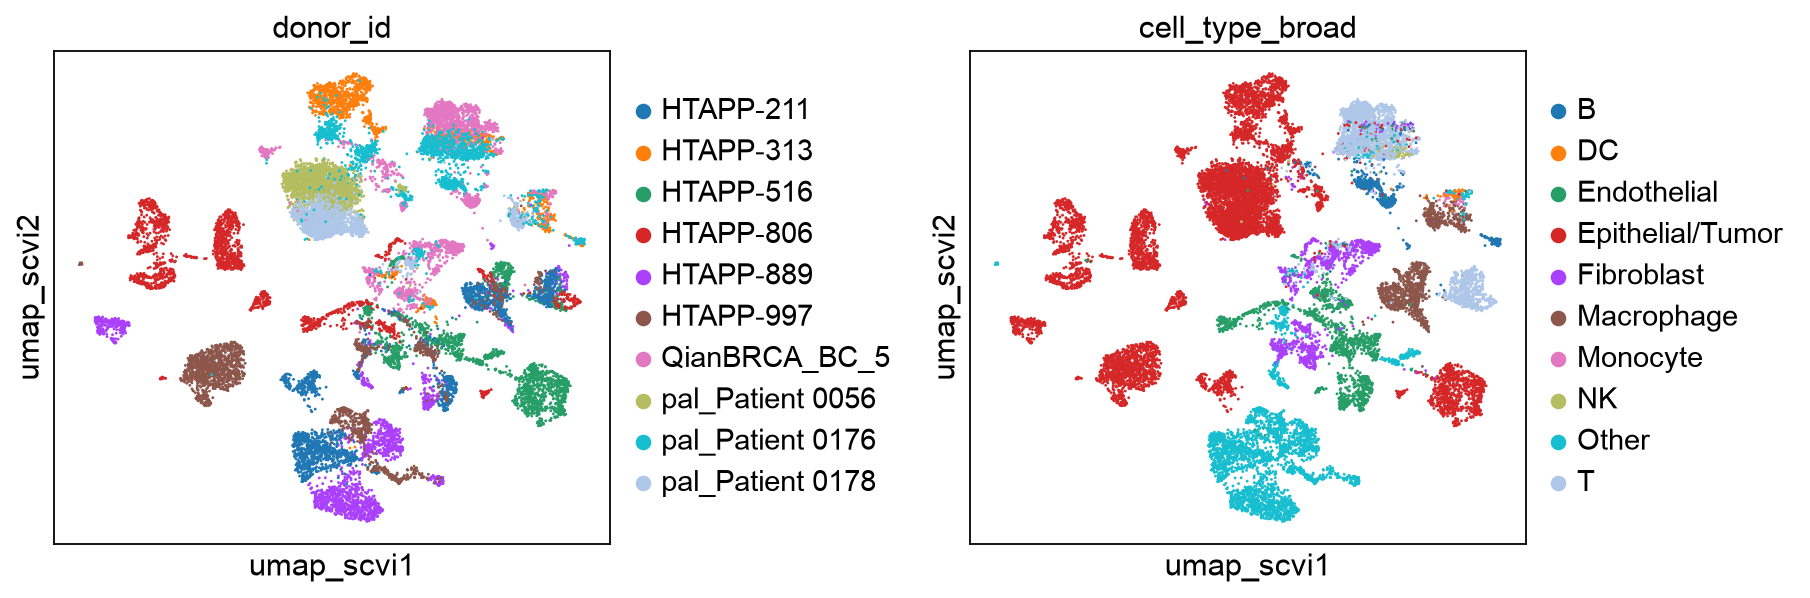

In [9]:
# TODO: plot the scVI UMAP colored by donor and by cell type. Did the donors mix?
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5)

## 1.5 · Harmony, a fair baseline  *(provided)*

In [10]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-17 00:12:31,661 - harmonypy - INFO - Running Harmony
2026-11-17 00:12:31,661 - harmonypy - INFO -   Parameters:
2026-11-17 00:12:31,662 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-17 00:12:31,662 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-17 00:12:31,662 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-17 00:12:31,662 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-17 00:12:31,662 - harmonypy - INFO -     nclust: 100
2026-11-17 00:12:31,662 - harmonypy - INFO -     block_size: 0.05
2026-11-17 00:12:31,663 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-17 00:12:31,663 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-11-17 00:12:31,663 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-17 00:12:31,663 - harmonypy - INFO -     verbose: True
2026-11-17 00:12:31,663 - harmonypy - INFO -     random_state: 0
2026-11-17 00:12:31,664 - harmonypy - INFO -   Data: 50 PCs × 18388 cells
2026-11-17 00:12:31,664 - 

Harmony done


## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

In [11]:
from sklearn.metrics import silhouette_score
# TODO: for each embedding, score batch mixing (by donor_id, lower is better)
#       and biology preservation (by cell_type_broad, higher is better).
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
scores = []
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    scores.append({"method": name, "batch_silhouette": round(batch, 3), "bio_silhouette": round(bio, 3)})
scores = pd.DataFrame(scores).set_index("method")
scores

,batch_silhouette,bio_silhouette
method,,
No integration,0.096,-0.008
Harmony,-0.087,0.007
scVI,-0.025,0.034


**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

I’d pick scVI, but it’s a close call.

Harmony mixes donors better batch silhouette goes from 0.096 to −0.087, while scVI only gets to −0.025. But scVI keeps the biology better, 0.034 against Harmony’s 0.007.

I’m weighting biology higher because what I actually need from this is reading which cell types express my target. Losing cell type separation would hurt more than a donor effect I can still see.

That said, all three bio scores are between −0.008 and 0.034, which is basically zero, so none of them is separating my labels cleanly. And I’m only using ten broad labels on 5,000 cells. So this is a rough comparison, not a strong result.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

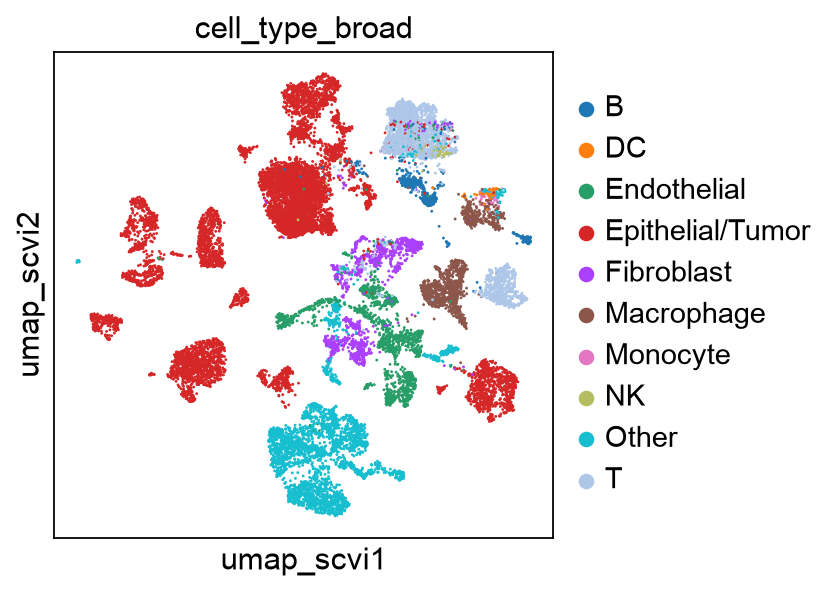

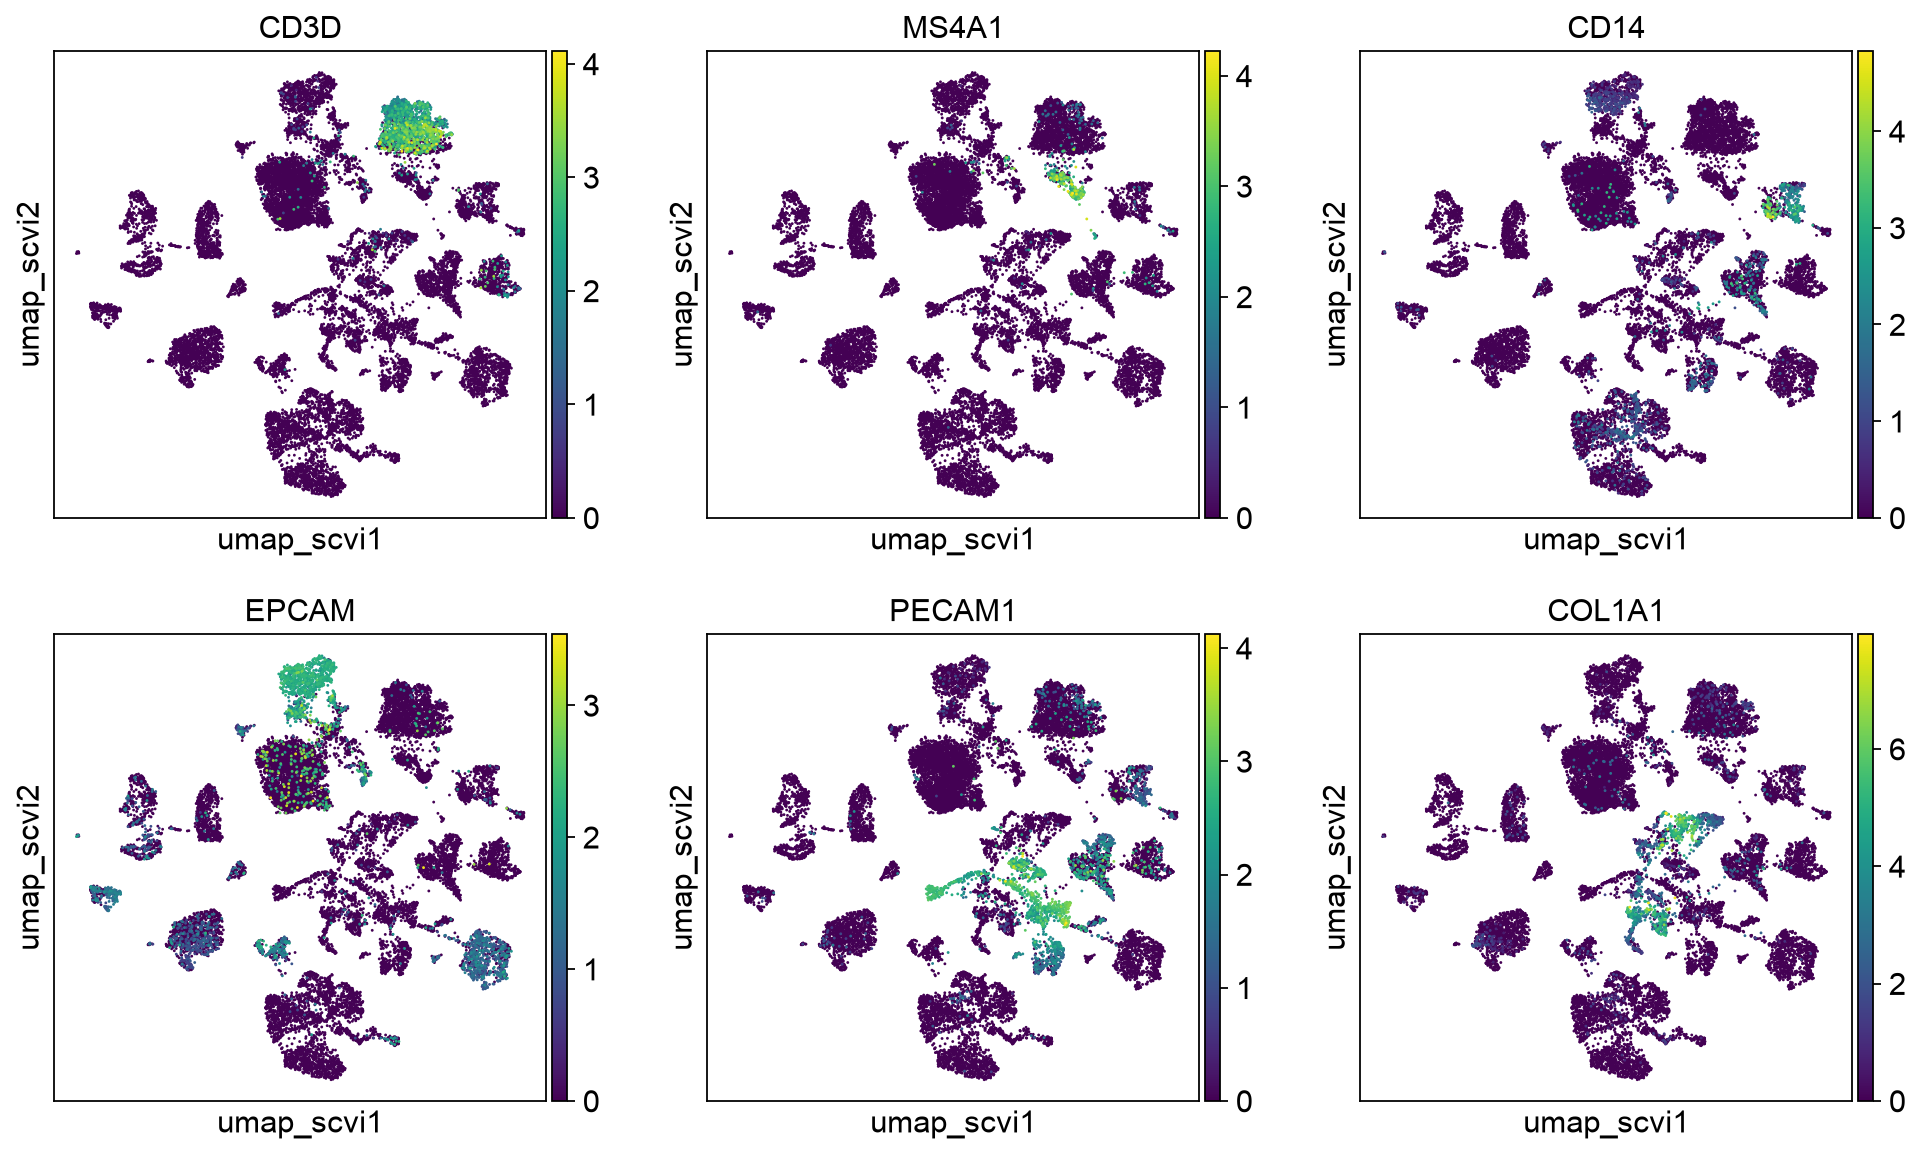

In [12]:
# TODO: plot the scVI UMAP colored by cell_type_broad, and by canonical markers.
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad")
markers = [g for g in ["CD3D","MS4A1","CD14","EPCAM","PECAM1","COL1A1"] if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

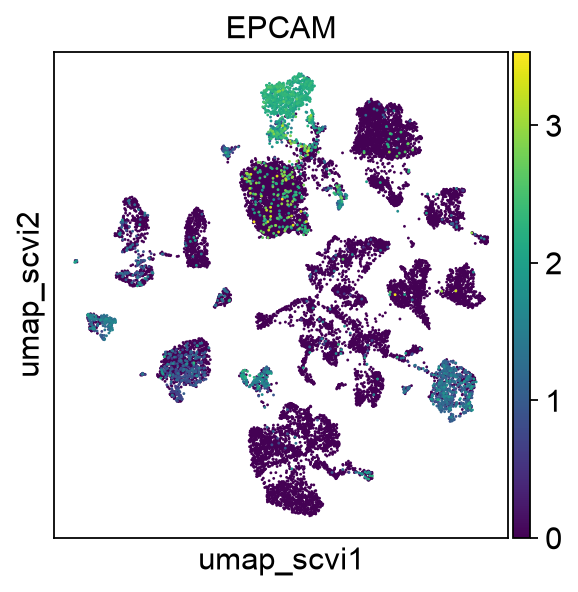

,mean_log_expr,pct_expressing
cell_type_broad,,
Epithelial/Tumor,0.47,29.27
DC,0.15,8.33
NK,0.05,2.00
Fibroblast,0.04,2.80
Other,0.03,1.81
T,0.03,1.44
B,0.02,1.13
Endothelial,0.02,1.19
Macrophage,0.02,1.09


In [13]:
TARGET = "EPCAM"   # TODO: choose your target: ERBB2, ESR1, EPCAM, MKI67, PTPRC, CD68, CD3D, or your Part I gene
# TODO: plot TARGET on the scVI UMAP.
sc.pl.embedding(adata, basis="umap_scvi", color=TARGET, use_raw=True)
# mean expression and % of cells expressing, per broad cell type
expr = pd.Series(adata.raw[:, TARGET].X.toarray().ravel(), index=adata.obs_names)
pd.DataFrame({"mean_log_expr": expr.groupby(adata.obs["cell_type_broad"], observed=True).mean(),
              "pct_expressing": (expr > 0).groupby(adata.obs["cell_type_broad"], observed=True).mean() * 100}).round(2).sort_values("mean_log_expr", ascending=False)

**TODO (interpretation):** Which cell type(s) express your target? 

EPCAM is almost entirely in the Epithelial/Tumour cells. 29% of them express it at a mean of 0.47, and everything else is between 0 and 8% - DCs are next at 8.3%, then T, B, macrophage, fibroblast and endothelial all sit around 1 to 3%, and monocytes show none.

29% seems low for a marker this canonical. I’d guess dropout is doing some of that, plus tumour cells that have gone through EMT and genuinely lost their epithelial markers.

For a target though, the contrast is what matters more than the absolute number. EPCAM is four times more likely to show up in tumour cells than in the next cell type, and more than twenty times more likely than in immune cells.


---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [14]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/var/folders/4_/88nmgg011p36zdz6mwstpv380000gn/T/ipykernel_50888/520941202.py:1: FutureWarning: Use `squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")


  0%|          | 0.00/9.50M [00:00<?, ?B/s]

  0%|          | 0.00/26.9M [00:00<?, ?B/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/scanpy/datasets/_datasets.py:555: FutureWarning: Use `squidpy.read.visium` instead.
  return read_visium(sample_dir, source_image_path=source_image_path)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
spots x genes: (3798, 36601)


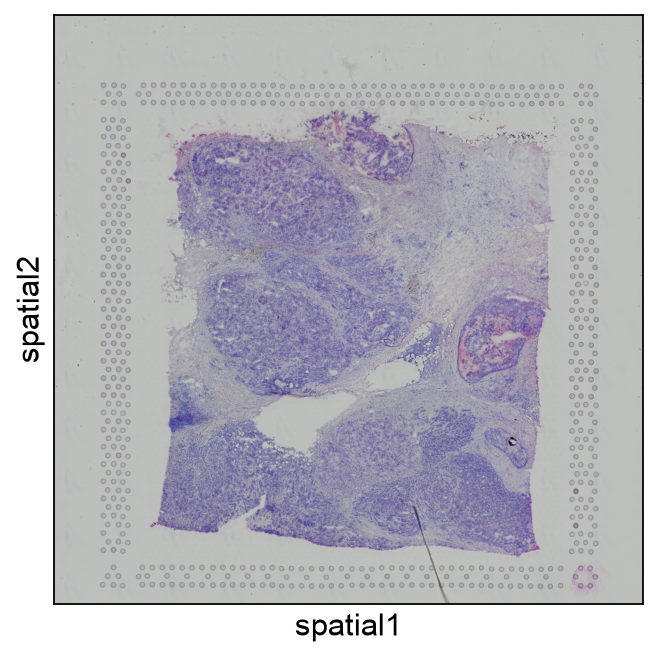

In [15]:
# spots over the H&E image
sq.pl.spatial_scatter(spatial)

## 2.2 · Pipeline and clustering  *(provided)*

In [16]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/var/folders/4_/88nmgg011p36zdz6mwstpv380000gn/T/ipykernel_50888/4117200164.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

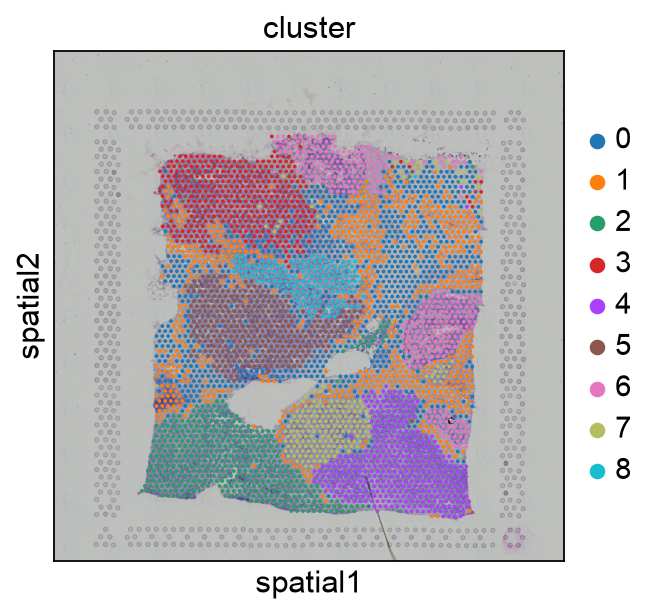

In [17]:
# TODO: plot the clusters on the tissue image.
sq.pl.spatial_scatter(spatial, color="cluster")

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

Yes, they do. Each domain sits in its own coherent patch rather than scattering across the section.

Cluster 4 in the lower right and cluster 3 in the upper left both sit over the densely stained parts of the H&E, so I read those as tumour nests. Clusters 0 and 1 are more diffuse, running through the middle and around those blocks, which looks like stroma. Cluster 2 is a band in the lower left and cluster 6 is a patch on the right.

I should say I’m reading these off the spatial pattern and the H&E rather than marker genes, so they’re provisional. Checking markers per domain would be the next step.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [18]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/var/folders/4_/88nmgg011p36zdz6mwstpv380000gn/T/ipykernel_50888/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


               I
MGP     0.868504
MALAT1  0.762550
CRISP3  0.726334
CPB1    0.711023
IGHG3   0.703817
IGLC2   0.700306
IGKC    0.680696
ALB     0.667866


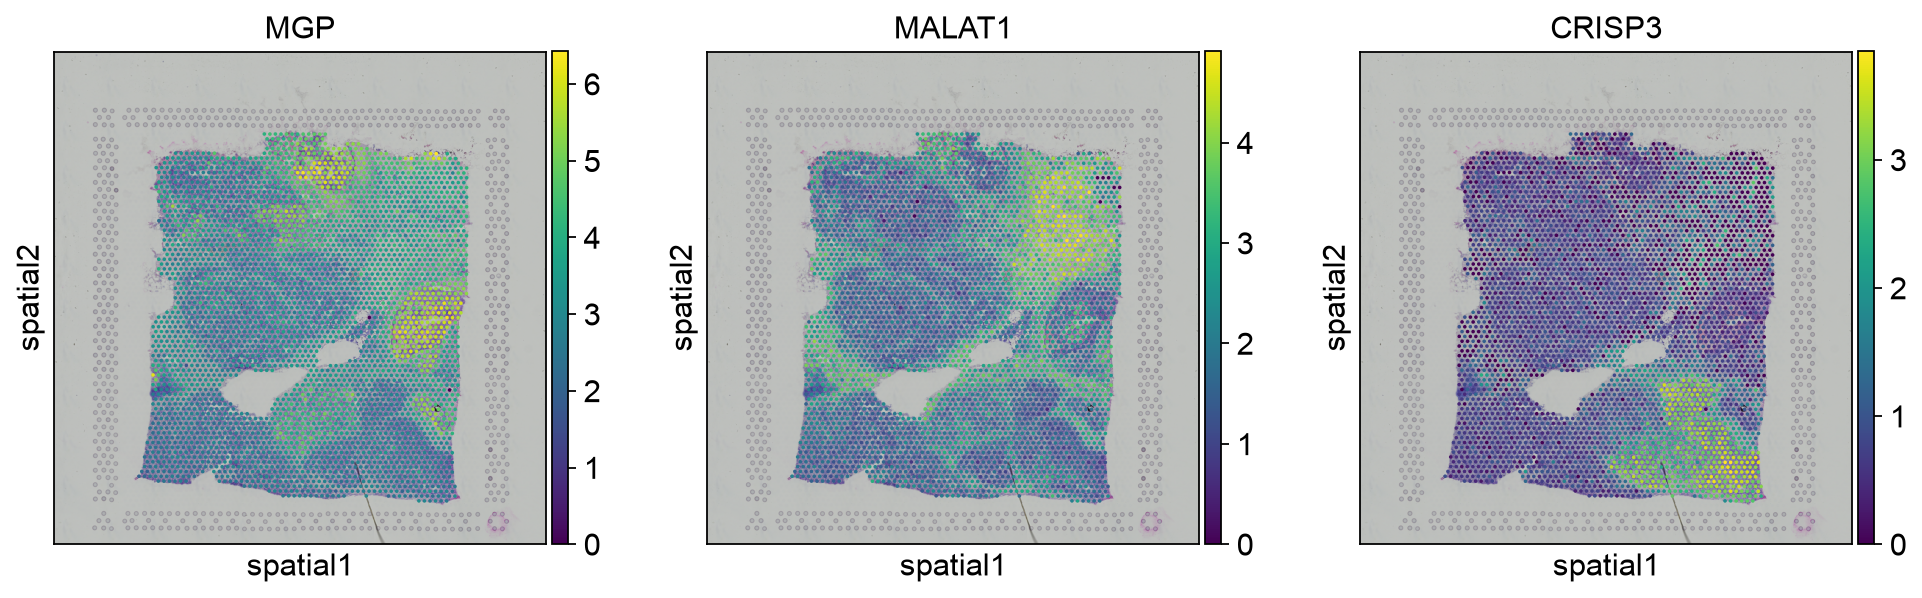

In [19]:
# TODO: compute Moran's I, print the top spatially variable genes, and plot 2-3 on the tissue.
sq.gr.spatial_autocorr(spatial, mode="moran")
top = spatial.uns["moranI"].head(8); print(top[["I"]])
sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist())

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

  0%|          | 0/1000 [00:00<?, ?/s]

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


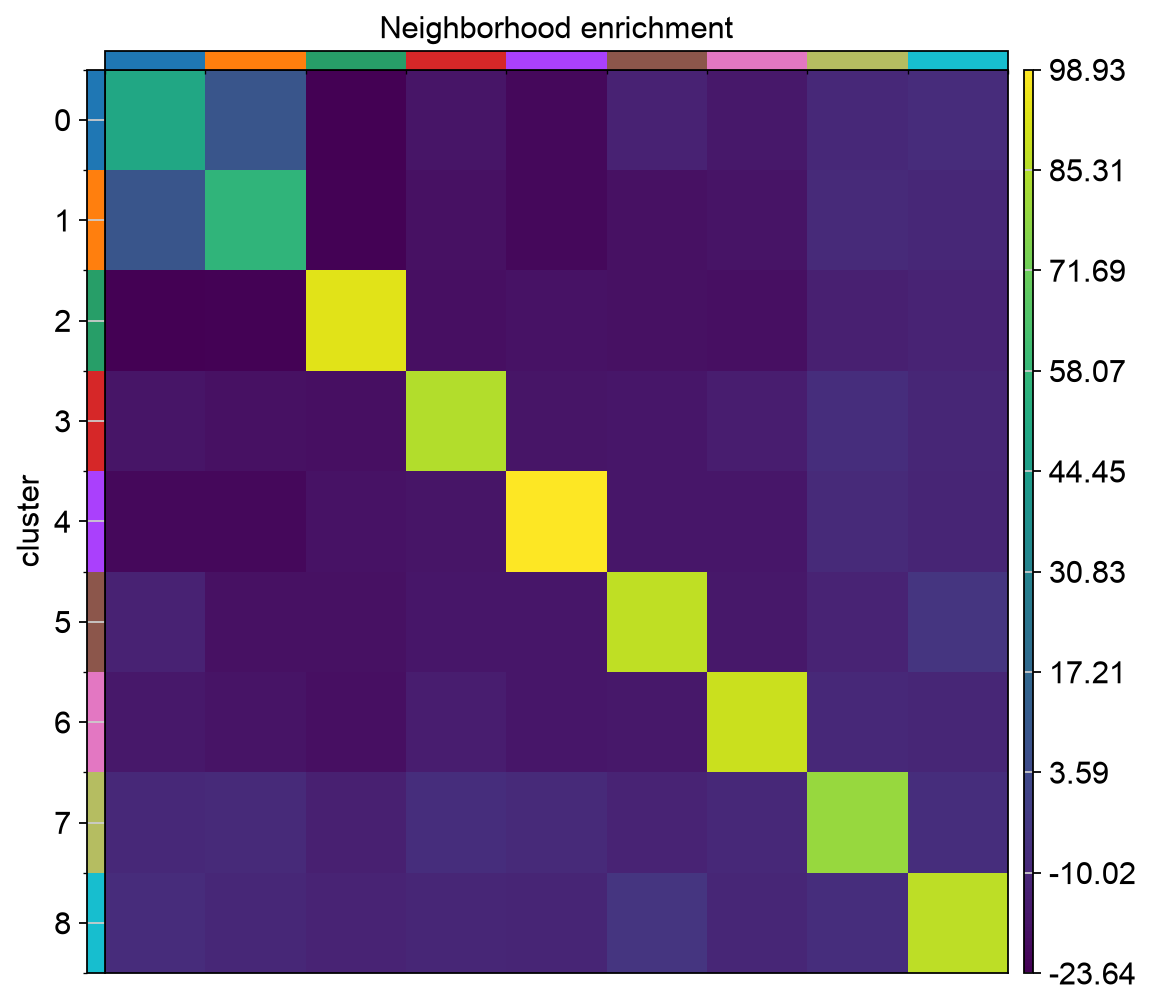

In [20]:
# TODO: run and plot neighborhood enrichment across the clusters.
sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster")

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

It’s mostly diagonal. Every domain is enriched next to itself, cluster 2 most strongly, so the domains form solid patches instead of interleaving.

The one off-diagonal signal worth noting is clusters 0 and 1. Since both are diffuse around the tumour blocks, I think that’s one stromal compartment that got split into two domains rather than two different tissues meeting.

The matrix doesn’t show a tumour-immune interface. But the Moran’s I results suggest one is there IGHG3 (0.704), IGLC2 (0.700) and IGKC (0.681) are all in the top eight, and they’re all immunoglobulin genes, which means plasma cells are present and clustered in space rather than scattered. So the immune niche exists, it just isn’t coming out as its own domain at this resolution.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

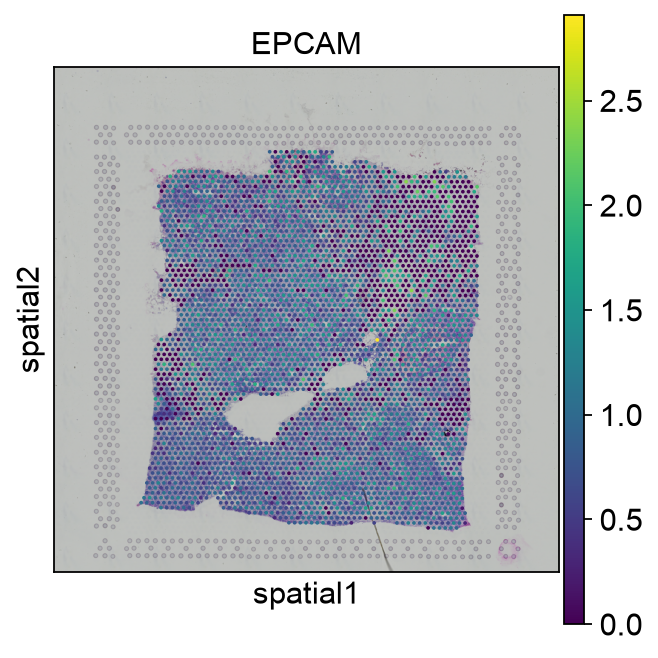

In [22]:
# TODO: plot TARGET on the tissue (if it is present in this section).
if TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(spatial, color=TARGET)
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")

**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

I’d call it tumour core.

EPCAM shows up across most of the section at low to moderate levels, strongest in the centre and upper area, weakest around the lower-left margin. It overlaps the dense tumour regions and thins out in the stromal bands between them, which is what I’d expect from an epithelial adhesion molecule sitting on the tumour cells.

That matters for whether you could drug it. A target spread through the core is hard to reach with a normal 150 kDa antibody, since those don’t penetrate solid tumours well and tend to accumulate near the vessels at the edge. Something at the invasive margin or on the vasculature would be much easier to hit.

One thing I’d flag: each Visium spot is about 55 µm and covers several cells, so every value is an average over whatever’s underneath it. I can’t tell whether a spot has lots of weak expressers or a few strong ones, and some of how even this looks might just be that averaging.


---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.